In [84]:
# Data Manipulation
import pandas as pd
import numpy as np

# Data Visulazation
import matplotlib.pyplot as plt
import seaborn as sns

# Data splitting
from sklearn.model_selection import train_test_split

# Data Scaling
from sklearn.preprocessing import RobustScaler

# Label Encoding
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import LabelEncoder

# Model Selection
from sklearn.model_selection import GridSearchCV

# Modling >> Machine Learning
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Deep learning
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

# Scoring (Evaluation)
from sklearn.metrics import accuracy_score , precision_score , recall_score , f1_score , confusion_matrix , classification_report






In [85]:
# Download Data
df = pd.read_csv('/content/bank-full.csv' , sep = ';')

# Data Understanding & Exploration

In [86]:
# Data Understanding
df.head() # First 5 rows

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [87]:
df.tail() # Last 5 rows

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


In [88]:
print(f" Number of rows : {df.shape[0]}" )# Number of rows

 Number of rows : 45211


In [89]:
print(f" Number of columns : {df.shape[1]}" )# Number of columns

 Number of columns : 17


In [90]:
df.columns  # Columns names

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'y'],
      dtype='object')

How many customers/records are in the dataset?

> there is 45211 records

How many features are available?
> there is 17 features

---



# Dataset Information

In [91]:
# Check Data information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [92]:
df.dtypes # Data types (each columns)


,0
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64


In [93]:
df.select_dtypes(include='number').columns # Numerical columns

Index(['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous'], dtype='object')

In [94]:
df.select_dtypes(include='object').columns # Categorical columns

Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome', 'y'],
      dtype='object')

In [95]:
# Check Missing values valuses for each column
df.isna().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


In [96]:
# Check summetion Null values for all data
df.isna().sum().sum()

np.int64(0)

In [97]:
# count number of uniqe values for each columns
df.nunique()

,0
age,77
job,12
marital,3
education,4
default,2
balance,7168
housing,2
loan,2
contact,3
day,31


In [98]:
# Show Unique values for categorical columns
for col in df.select_dtypes(include='object'):
  print (f"{df[col].value_counts()}" )
  print('-'*20)

job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64
--------------------
marital
married     27214
single      12790
divorced     5207
Name: count, dtype: int64
--------------------
education
secondary    23202
tertiary     13301
primary       6851
unknown       1857
Name: count, dtype: int64
--------------------
default
no     44396
yes      815
Name: count, dtype: int64
--------------------
housing
yes    25130
no     20081
Name: count, dtype: int64
--------------------
loan
no     37967
yes     7244
Name: count, dtype: int64
--------------------
contact
cellular     29285
unknown      13020
telephone     2906
Name: count, dtype: int64
--------------------
month
may    13766
jul     6895
aug     6247
jun     5341
nov     3970
apr     2932
feb    

In [99]:
# Check Duplication
df.duplicated().sum()


np.int64(0)

* **There are no missing (null) values**: The dataset is 100% complete.
* **There is no duplicated data**: Every row is unique and independent.
* **Categorical (object) columns are completely clean**: The unique values are clear with no spelling errors (such as variations in capitalization or duplicate entries with different spellings) and there is not datatimes refers as object








* Numerical columns is numerical.
* Categorical columns is categorical/object.
* there is no Dates , datetime

# Data Cleaning (Preprocessing)

 **Task 3: Missing Values**
1. Are there missing values?
> No, there are no missing values in the dataset.

2. Which columns contain missing/unknown values?
> None.

3. How will you handle them? (General Strategy)
> If missing values account for a very small percentage of the data, we drop those rows.

>> If a column has more than 50% missing values, we drop the entire column.

>> **For categorical columns** with substantial missing data, we fill them using the mode (most frequent value).

>> **For numerical columns** with substantial missing data, we first **check for outliers**:
>>> If outliers are present and cannot be dropped, we fill missing values using the median (since it is robust to outliers).

>>> If the data is free of significant outliers, we fill missing values using the mean.

**Task 4: Duplicate Records**
1. Check whether duplicate rows exist.
> There is no duplicates rows
2. If duplicates exist Identify them :
>  None
3. Determine whether they should be removed.
> df.drop_duplicates()


In [100]:
# Drop features that are not necessary for modeling:
# - day: There is no significant difference if the campaign happens on the 3rd or 5th day.
# - duration: Must be dropped to prevent data leakage, as we want to predict if a customer will accept BEFORE we make the call.

df.drop(columns=['day' , 'duration'] , axis=1 , inplace=True)

In [101]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'month', 'campaign', 'pdays', 'previous', 'poutcome',
       'y'],
      dtype='object')

## Task 6: Outlier Detection

In [102]:

numerical_columns = df.select_dtypes(include='number')

for col in numerical_columns:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5*IQR
  upper_bound = Q3 + 1.5*IQR
  outliers=df[(df[col]<lower_bound) | (df[col]>upper_bound)]
  percentage = len(outliers)/len(df)*100
  print(
      f'Column [{col}]: Found {len(outliers)} outliers ({percentage:.2f}%).'
  )


Column [age]: Found 487 outliers (1.08%).
Column [balance]: Found 4729 outliers (10.46%).
Column [campaign]: Found 3064 outliers (6.78%).
Column [pdays]: Found 8257 outliers (18.26%).
Column [previous]: Found 8257 outliers (18.26%).


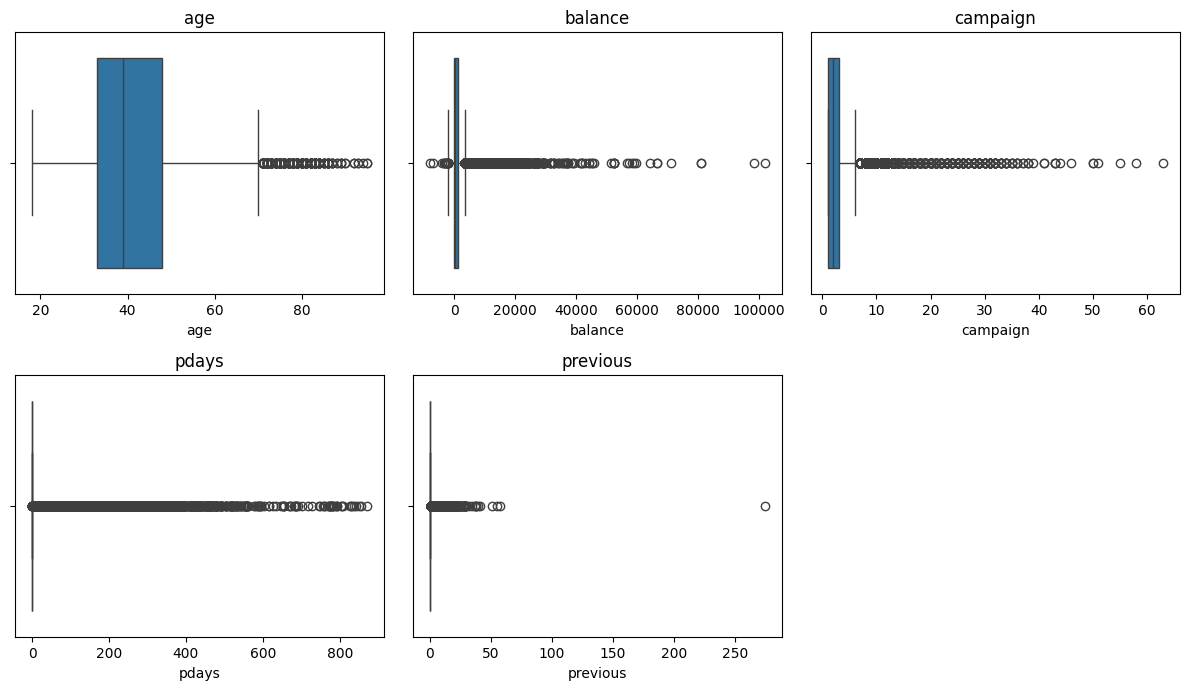

In [103]:
# Visulaztion of outliers
plt.figure(figsize=(12,10))
for i , col in enumerate(numerical_columns,start=1):
  plt.subplot(3,3,i)
  sns.boxplot(
      x=col , data=df
  )
  plt.title(col)

plt.tight_layout()
plt.show()

# PART 3 — Exploratory Data Analysis - EDA

In [104]:
df.describe(include='object')

,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,45211,45211,45211,45211,45211,45211,45211,45211,45211,45211
unique,12,3,4,2,2,2,3,12,4,2
top,blue-collar,married,secondary,no,yes,no,cellular,may,unknown,no
freq,9732,27214,23202,44396,25130,37967,29285,13766,36959,39922


In [105]:
df.describe(include='number')

,age,balance,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,2.763841,40.197828,0.580323
std,10.618762,3044.765829,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,63.000000,871.000000,275.000000


In [106]:
# Chech imbalance in date

df['y'].value_counts()

,count
y,
no,39922
yes,5289


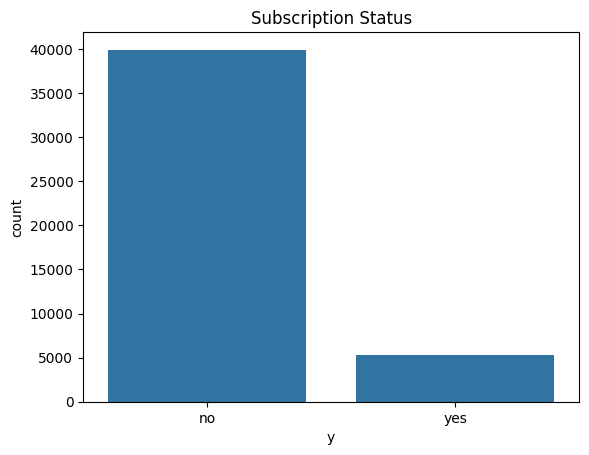

In [107]:
sns.countplot(data=df , x='y')
plt.title('Subscription Status')
plt.show()

In [108]:
subscribed_percentage =(df['y']=='yes').sum() / len(df) * 100
not_subscribed_percentage =(df['y']=='no').sum() / len(df) * 100
print(f"Percentage of customers who subscribed: {subscribed_percentage:.2f}%")
print(f"Percentage of customers who did not subscribe: {not_subscribed_percentage:.2f}%")


Percentage of customers who subscribed: 11.70%
Percentage of customers who did not subscribe: 88.30%


The target is imbalanced so that will be problem in Machine Learning (Overfitting in majority (yes)

In [109]:
# Mapping of target (Encoding)
df['y']=df['y'].map({'yes':1,'no':0})

In [110]:
df

,age,job,marital,education,default,balance,housing,loan,contact,month,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,may,1,-1,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,may,1,-1,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,may,1,-1,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,may,1,-1,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,may,1,-1,0,unknown,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,cellular,nov,3,-1,0,unknown,1
45207,71,retired,divorced,primary,no,1729,no,no,cellular,nov,2,-1,0,unknown,1
45208,72,retired,married,secondary,no,5715,no,no,cellular,nov,5,184,3,success,1
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,nov,4,-1,0,unknown,0


# PART 4 — Data Visualization

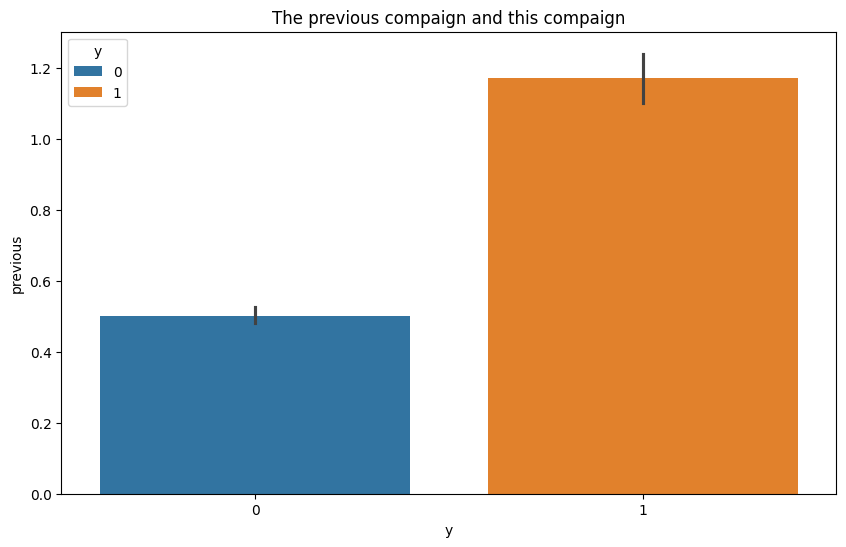

In [111]:
plt.figure(figsize=(10, 6))
sns.barplot(data=df, x="y", y="previous", hue="y")
plt.title('The previous compaign and this compaign')
plt.show()

 Customers who accepted the offer (y=1) have a higher average number of previous contacts compared to those who rejected it (y=0).

---







/tmp/ipykernel_2614/792911363.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='job', y='y',ci=None)


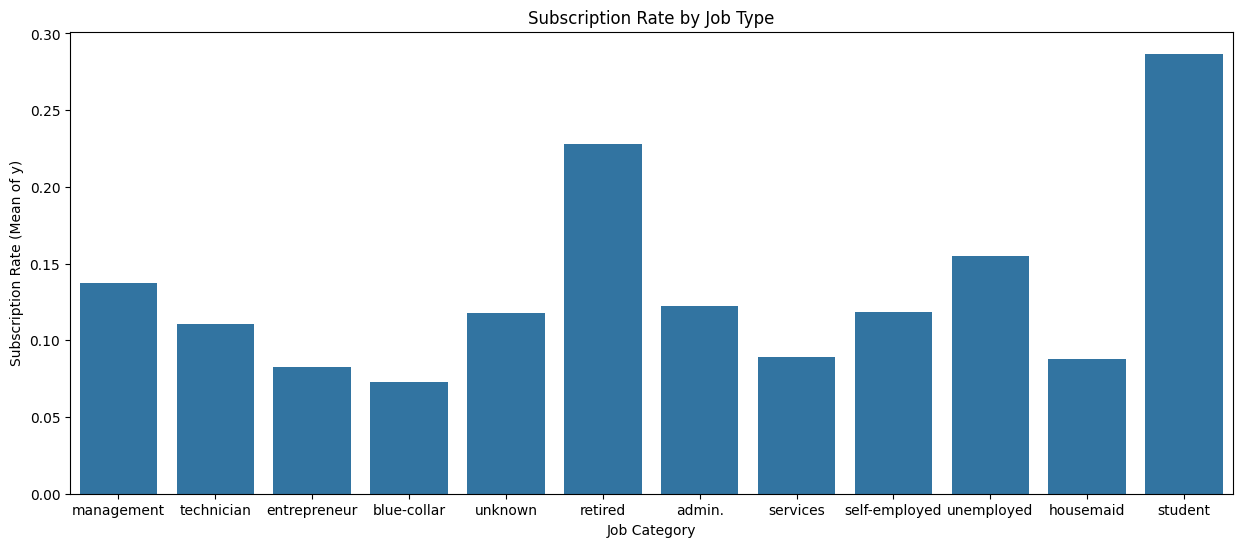

In [112]:
plt.figure(figsize=(15, 6))
sns.barplot(data=df, x='job', y='y',ci=None)
plt.title('Subscription Rate by Job Type')
plt.xlabel('Job Category')
plt.ylabel('Subscription Rate (Mean of y)')
plt.show()

 Students show the highest subscription rate ~(29%), while blue-collar workers have the lowest ~(7%).



---



/tmp/ipykernel_2614/3320121053.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='education', y='y', ci=None)


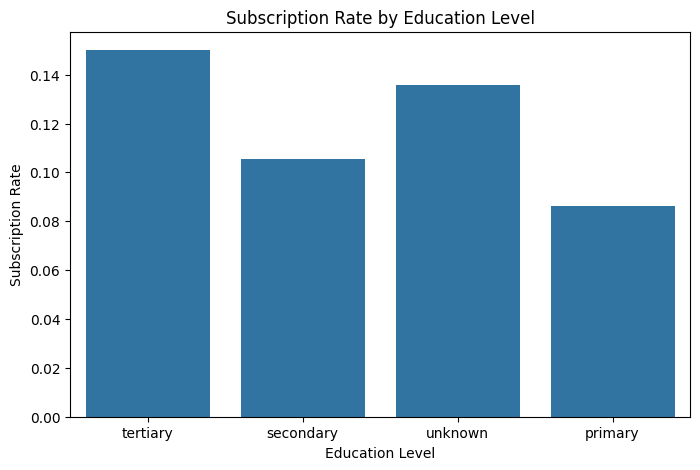

In [113]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='education', y='y', ci=None)
plt.title('Subscription Rate by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Subscription Rate')
plt.show()

Customers with tertiary education levels are often more understanding of long-term investment products and quicker to respond.


---



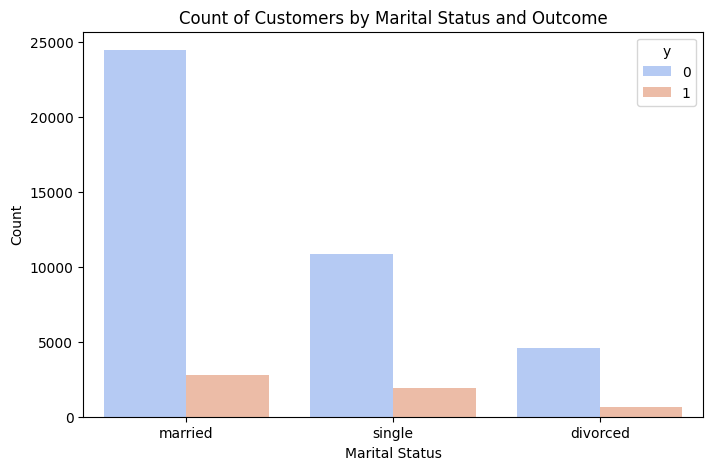

In [114]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='marital', hue='y', palette='coolwarm')
plt.title('Count of Customers by Marital Status and Outcome')
plt.xlabel('Marital Status')
plt.ylabel('Count')
plt.show()

 Married customers represent the largest segment in the dataset, leading to the highest total counts for both rejections (y=0) and acceptances (y=1), followed by single and divorced customers.


---



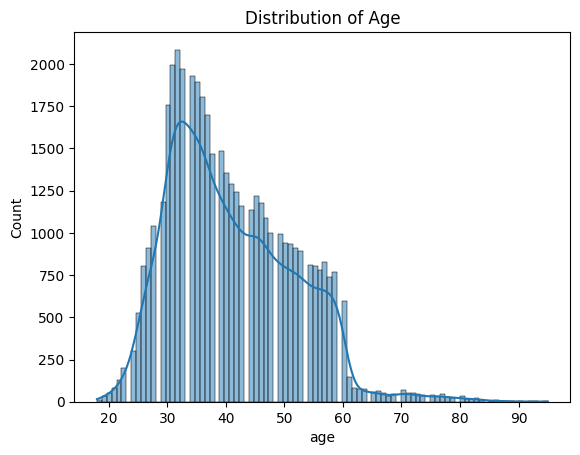

In [115]:
sns.histplot(data=df , x='age' , kde=True)
plt.title('Distribution of Age')
plt.show()

In [116]:
# Feature Engineering (Age)
def AgeGroup ( age):
  if age <= 20:
    return 'young'
  elif  20 < age < 30 :
    return 'adult'
  elif 30<= age<= 50 :
    return 'middle_age'
  else :
    return 'senior'

df['age_group'] = df['age'].apply(AgeGroup)

In [117]:
df.sample(5)

,age,job,marital,education,default,balance,housing,loan,contact,month,campaign,pdays,previous,poutcome,y,age_group
36702,39,management,married,tertiary,no,266,yes,yes,cellular,may,1,-1,0,unknown,0,middle_age
26375,34,entrepreneur,married,secondary,no,455,yes,no,cellular,nov,1,-1,0,unknown,0,middle_age
25279,33,management,married,tertiary,no,1522,yes,no,cellular,nov,2,179,3,failure,0,middle_age
13629,35,technician,single,tertiary,no,364,no,yes,cellular,jul,3,-1,0,unknown,0,middle_age
35392,51,technician,married,secondary,no,-1944,yes,no,cellular,may,1,-1,0,unknown,1,senior


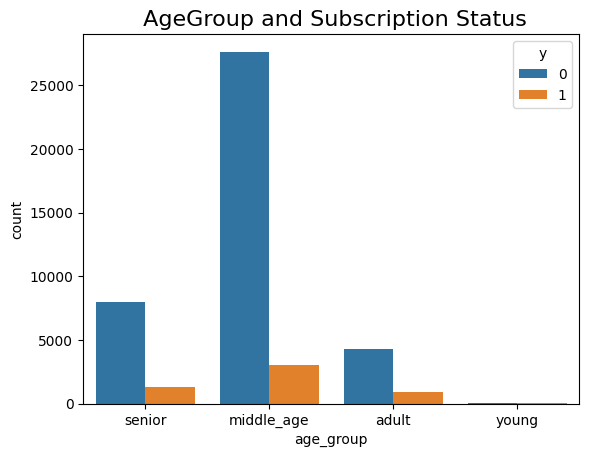

In [118]:
sns.countplot(data=df , x='age_group', hue='y')
plt.title(' AgeGroup and Subscription Status', fontsize=16)
plt.show()

 The 'middle_age' group dominates the dataset in total volume and subscriptions (y=1), followed by senior and adult groups, while young customers have the lowest representation.

---



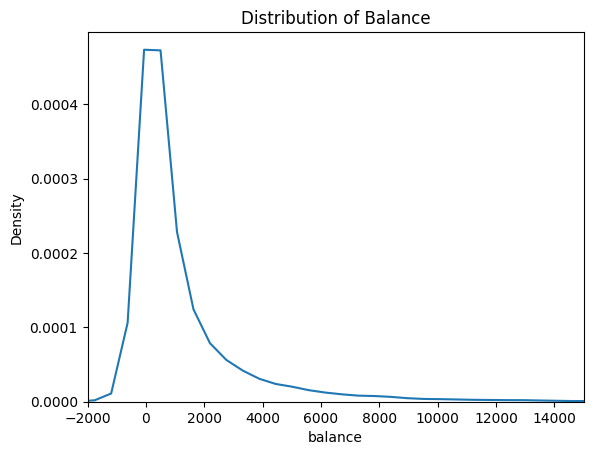

In [119]:
sns.kdeplot(data=df , x='balance')
plt.xlim(-2000, 15000)
plt.title('Distribution of Balance')
plt.show()

In [120]:
# Feature Engineering (Balance)
def BalanceCategory (balance):
  if balance < 0:
    return 'debt'
  elif  0 <= balance <= 2000 :
    return 'low'
  elif 2000 < balance < 8000 :
    return 'medium'
  else :
    return 'high'

df['balance_group'] = df['balance'].apply(BalanceCategory)

In [121]:
df.sample(5)

,age,job,marital,education,default,balance,housing,loan,contact,month,campaign,pdays,previous,poutcome,y,age_group,balance_group
39650,25,admin.,married,tertiary,no,906,no,no,cellular,may,1,-1,0,unknown,1,adult,low
23938,54,technician,married,secondary,no,1670,no,no,cellular,aug,7,-1,0,unknown,0,senior,low
13372,36,blue-collar,married,secondary,no,199,yes,no,cellular,jul,1,-1,0,unknown,0,middle_age,low
18902,38,management,married,tertiary,no,691,yes,yes,cellular,aug,1,-1,0,unknown,0,middle_age,low
5314,31,management,married,tertiary,no,7,yes,no,unknown,may,1,-1,0,unknown,0,middle_age,low


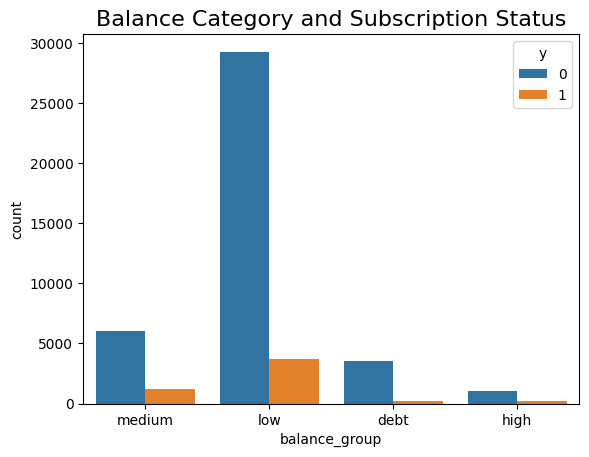

In [122]:
sns.countplot(data=df , x='balance_group', hue='y')
plt.title('Balance Category and Subscription Status', fontsize=16)
plt.show()

 The 'low' balance group dominates the dataset in total volume and subscriptions (y=1), followed by the 'medium' group, while 'debt' and 'high' balance categories have significantly fewer customers.



---



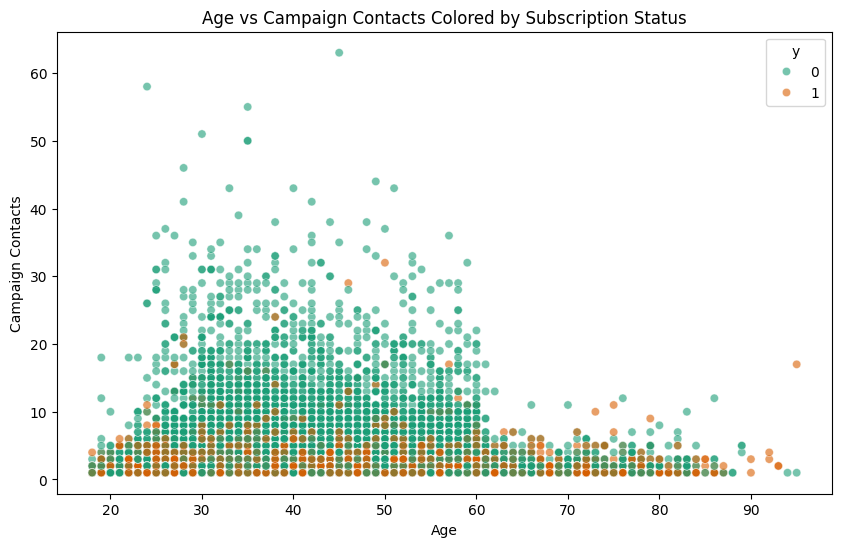

In [123]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='age', y='campaign', hue='y', alpha=0.6, palette='Dark2')
plt.title('Age vs Campaign Contacts Colored by Subscription Status')
plt.xlabel('Age')
plt.ylabel('Campaign Contacts')
plt.show()

In [124]:
# Feature Engineering (compaign)
def categorize_campaign(campaign_count):
  if campaign_count <= 2:
    return 'Low'
  elif 2 < campaign_count <= 5:
    return 'Medium'
  else:
    return 'High'

df['campaign_category'] = df['campaign'].apply(categorize_campaign)
df[['campaign','campaign_category']].sample(5)


,campaign,campaign_category
36738,1,Low
21427,2,Low
29070,7,High
26358,1,Low
43758,2,Low


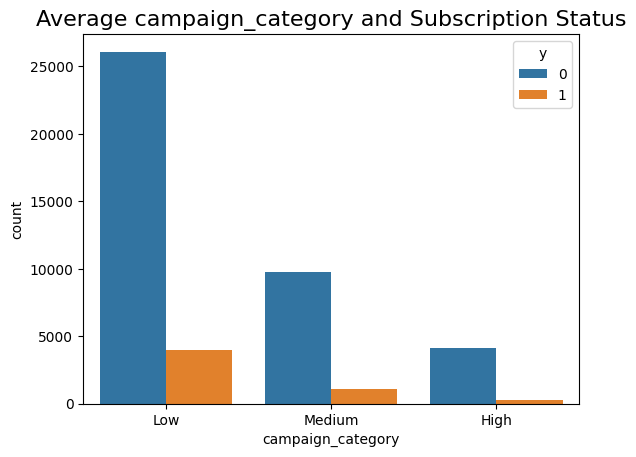

In [125]:
sns.countplot(data=df , x='campaign_category', hue='y')
plt.title('Average campaign_category and Subscription Status', fontsize=16)
plt.show()

 The 'Low' campaign category dominates the dataset in total volume and successful subscriptions (y=1), showing that fewer contacts per campaign yield higher success, while 'High' campaign contacts drop sharply in conversion.

---



In [126]:
df.sample(10)

,age,job,marital,education,default,balance,housing,loan,contact,month,campaign,pdays,previous,poutcome,y,age_group,balance_group,campaign_category
37467,47,blue-collar,divorced,primary,no,409,yes,no,cellular,may,2,364,1,other,0,middle_age,low,Low
32043,32,blue-collar,married,secondary,no,180,yes,no,cellular,apr,1,334,1,other,0,middle_age,low,Low
29950,28,admin.,married,secondary,no,568,yes,no,cellular,feb,6,252,4,other,0,adult,low,High
18968,59,blue-collar,married,primary,no,3713,yes,yes,cellular,aug,2,-1,0,unknown,0,senior,medium,Low
10946,50,housemaid,married,tertiary,no,6181,no,no,unknown,jun,2,-1,0,unknown,0,middle_age,medium,Low
30456,47,admin.,single,tertiary,no,178,no,no,telephone,feb,6,-1,0,unknown,0,middle_age,low,High
26851,45,blue-collar,single,unknown,no,816,no,no,cellular,nov,3,-1,0,unknown,0,middle_age,low,Medium
10638,39,self-employed,single,tertiary,no,0,no,no,unknown,jun,1,-1,0,unknown,0,middle_age,low,Low
32187,34,technician,single,secondary,no,2660,yes,no,cellular,apr,2,329,1,failure,0,middle_age,medium,Low
18026,60,retired,divorced,secondary,no,1091,no,no,cellular,jul,5,-1,0,unknown,1,senior,low,Medium


In [127]:
# Drop engineered categorical features to avoid multicollinearity; keeping original continuous variables
df=df.drop(columns=['age_group','balance_group','campaign_category'] , axis=1)

In [128]:
df

,age,job,marital,education,default,balance,housing,loan,contact,month,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,may,1,-1,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,may,1,-1,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,may,1,-1,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,may,1,-1,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,may,1,-1,0,unknown,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,cellular,nov,3,-1,0,unknown,1
45207,71,retired,divorced,primary,no,1729,no,no,cellular,nov,2,-1,0,unknown,1
45208,72,retired,married,secondary,no,5715,no,no,cellular,nov,5,184,3,success,1
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,nov,4,-1,0,unknown,0


# Machine Learning

In [129]:
# Split Data to >> feature and target (x,y)
x= df.drop(columns=['y'])
y= df['y']

In [130]:
# Split (x,y)>> train and test
x_train , x_test , y_train , y_test = train_test_split(x , y , test_size=0.2 , random_state=42)

## Encoding

In [131]:
# One-Hot Encoding to nominal categorical features (multi-class variables without a specific ranking logic)
categorical_columns = ['job' , 'marital' , 'education' , 'contact' , 'month' ,'poutcome']

onehot_encoder= OneHotEncoder(sparse_output= False , drop='first' , handle_unknown='ignore')

encoded_xtrain = onehot_encoder.fit_transform(x_train[categorical_columns])
encoded_xtest = onehot_encoder.transform(x_test[categorical_columns])

encoded_xtrain_df = pd.DataFrame(encoded_xtrain , columns=onehot_encoder.get_feature_names_out(categorical_columns),index=x_train.index)
encoded_xtest_df = pd.DataFrame(encoded_xtest , columns=onehot_encoder.get_feature_names_out(categorical_columns),index=x_test.index)

x_train = pd.concat([x_train.drop(columns=categorical_columns) , encoded_xtrain_df] , axis=1)
x_test = pd.concat([x_test.drop(columns=categorical_columns) , encoded_xtest_df] , axis=1)




In [132]:
x_train.head()

,age,default,balance,housing,loan,campaign,pdays,previous,job_blue-collar,job_entrepreneur,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
3344,41,no,849,yes,no,1,-1,0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
17965,49,no,1415,yes,no,2,-1,0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
18299,42,no,3842,no,no,4,-1,0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
10221,37,no,-119,yes,no,11,-1,0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
32192,56,no,3498,no,no,2,-1,0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [133]:
# label Encoding to binary catecategorical features (yes , no)
categorical_columns =['default' , 'housing' ,	'loan']

label_encoder = LabelEncoder()

for col in categorical_columns:
  x_train[col] = label_encoder.fit_transform(x_train[col])
  x_test[col] = label_encoder.transform(x_test[col])



In [134]:
x_train.head()

,age,default,balance,housing,loan,campaign,pdays,previous,job_blue-collar,job_entrepreneur,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
3344,41,0,849,1,0,1,-1,0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
17965,49,0,1415,1,0,2,-1,0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
18299,42,0,3842,0,0,4,-1,0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
10221,37,0,-119,1,0,11,-1,0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
32192,56,0,3498,0,0,2,-1,0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


## Scaling

In [135]:
num_cols = ['age' , 'balance', 'campaign' ,'pdays', 'previous']

scaler = RobustScaler()
x_train[num_cols] = scaler.fit_transform(x_train[num_cols])
x_test[num_cols]  = scaler.transform(x_test[num_cols])

In [136]:
x_train.head()

,age,default,balance,housing,loan,campaign,pdays,previous,job_blue-collar,job_entrepreneur,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
3344,0.133333,0,0.295806,1,0,-0.5,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
17965,0.666667,0,0.712288,1,0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
18299,0.200000,0,2.498160,0,0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
10221,-0.133333,0,-0.416483,1,0,4.5,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
32192,1.133333,0,2.245033,0,0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


## Correlation

In [137]:
# Combine X_train and y_train temporarily
train_data = x_train.copy()
train_data['target'] = y_train

# Correlation with target
correlation = train_data.corr(numeric_only=True)['target'].sort_values(ascending=False)

print(correlation)

target                 1.000000
poutcome_success       0.305084
month_oct              0.130183
month_mar              0.127642
month_sep              0.124370
pdays                  0.105742
previous               0.092051
month_dec              0.077569
job_retired            0.076440
job_student            0.073606
education_tertiary     0.065868
marital_single         0.061856
balance                0.052518
poutcome_other         0.035207
month_feb              0.031607
job_management         0.030974
age                    0.026684
job_unemployed         0.023566
contact_telephone      0.017208
education_unknown      0.007343
job_self-employed      0.004072
job_unknown           -0.001127
month_aug             -0.006371
month_jan             -0.009773
job_technician        -0.010275
job_housemaid         -0.011729
month_nov             -0.014124
job_entrepreneur      -0.016888
month_jun             -0.019750
default               -0.023934
job_services          -0.025259
month_ju


    'education_unknown' >> weak positive relasionship
    'job_self-employed' >> weak positive relasionship
    'job_unknown' >> weak negative relasionship
    'month_aug' >> weak negative relasionship
    'month_jan' >>  weak negative relasionship


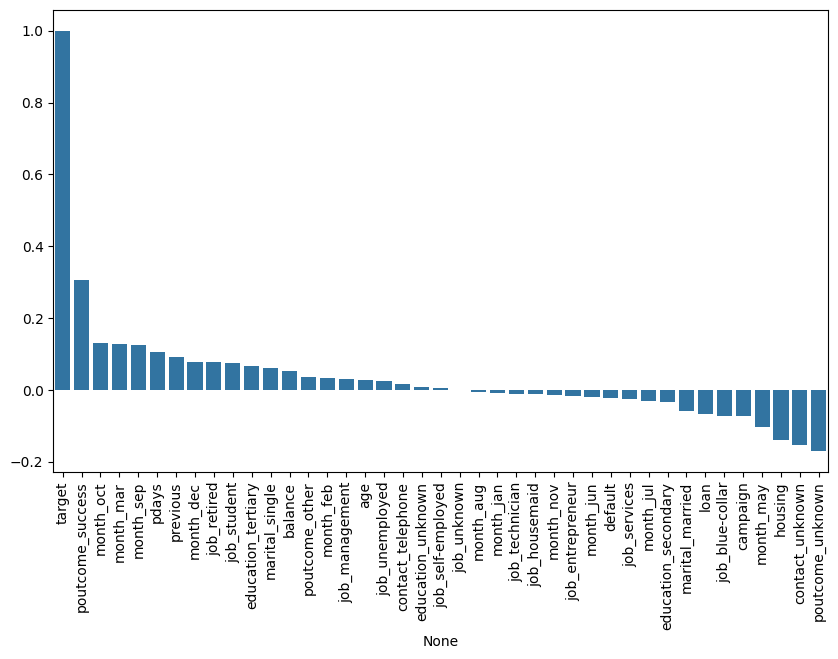

In [138]:
plt.figure(figsize=(10, 6))
sns.barplot(x=correlation.index, y=correlation.values)
plt.xticks(rotation=90)
plt.show()

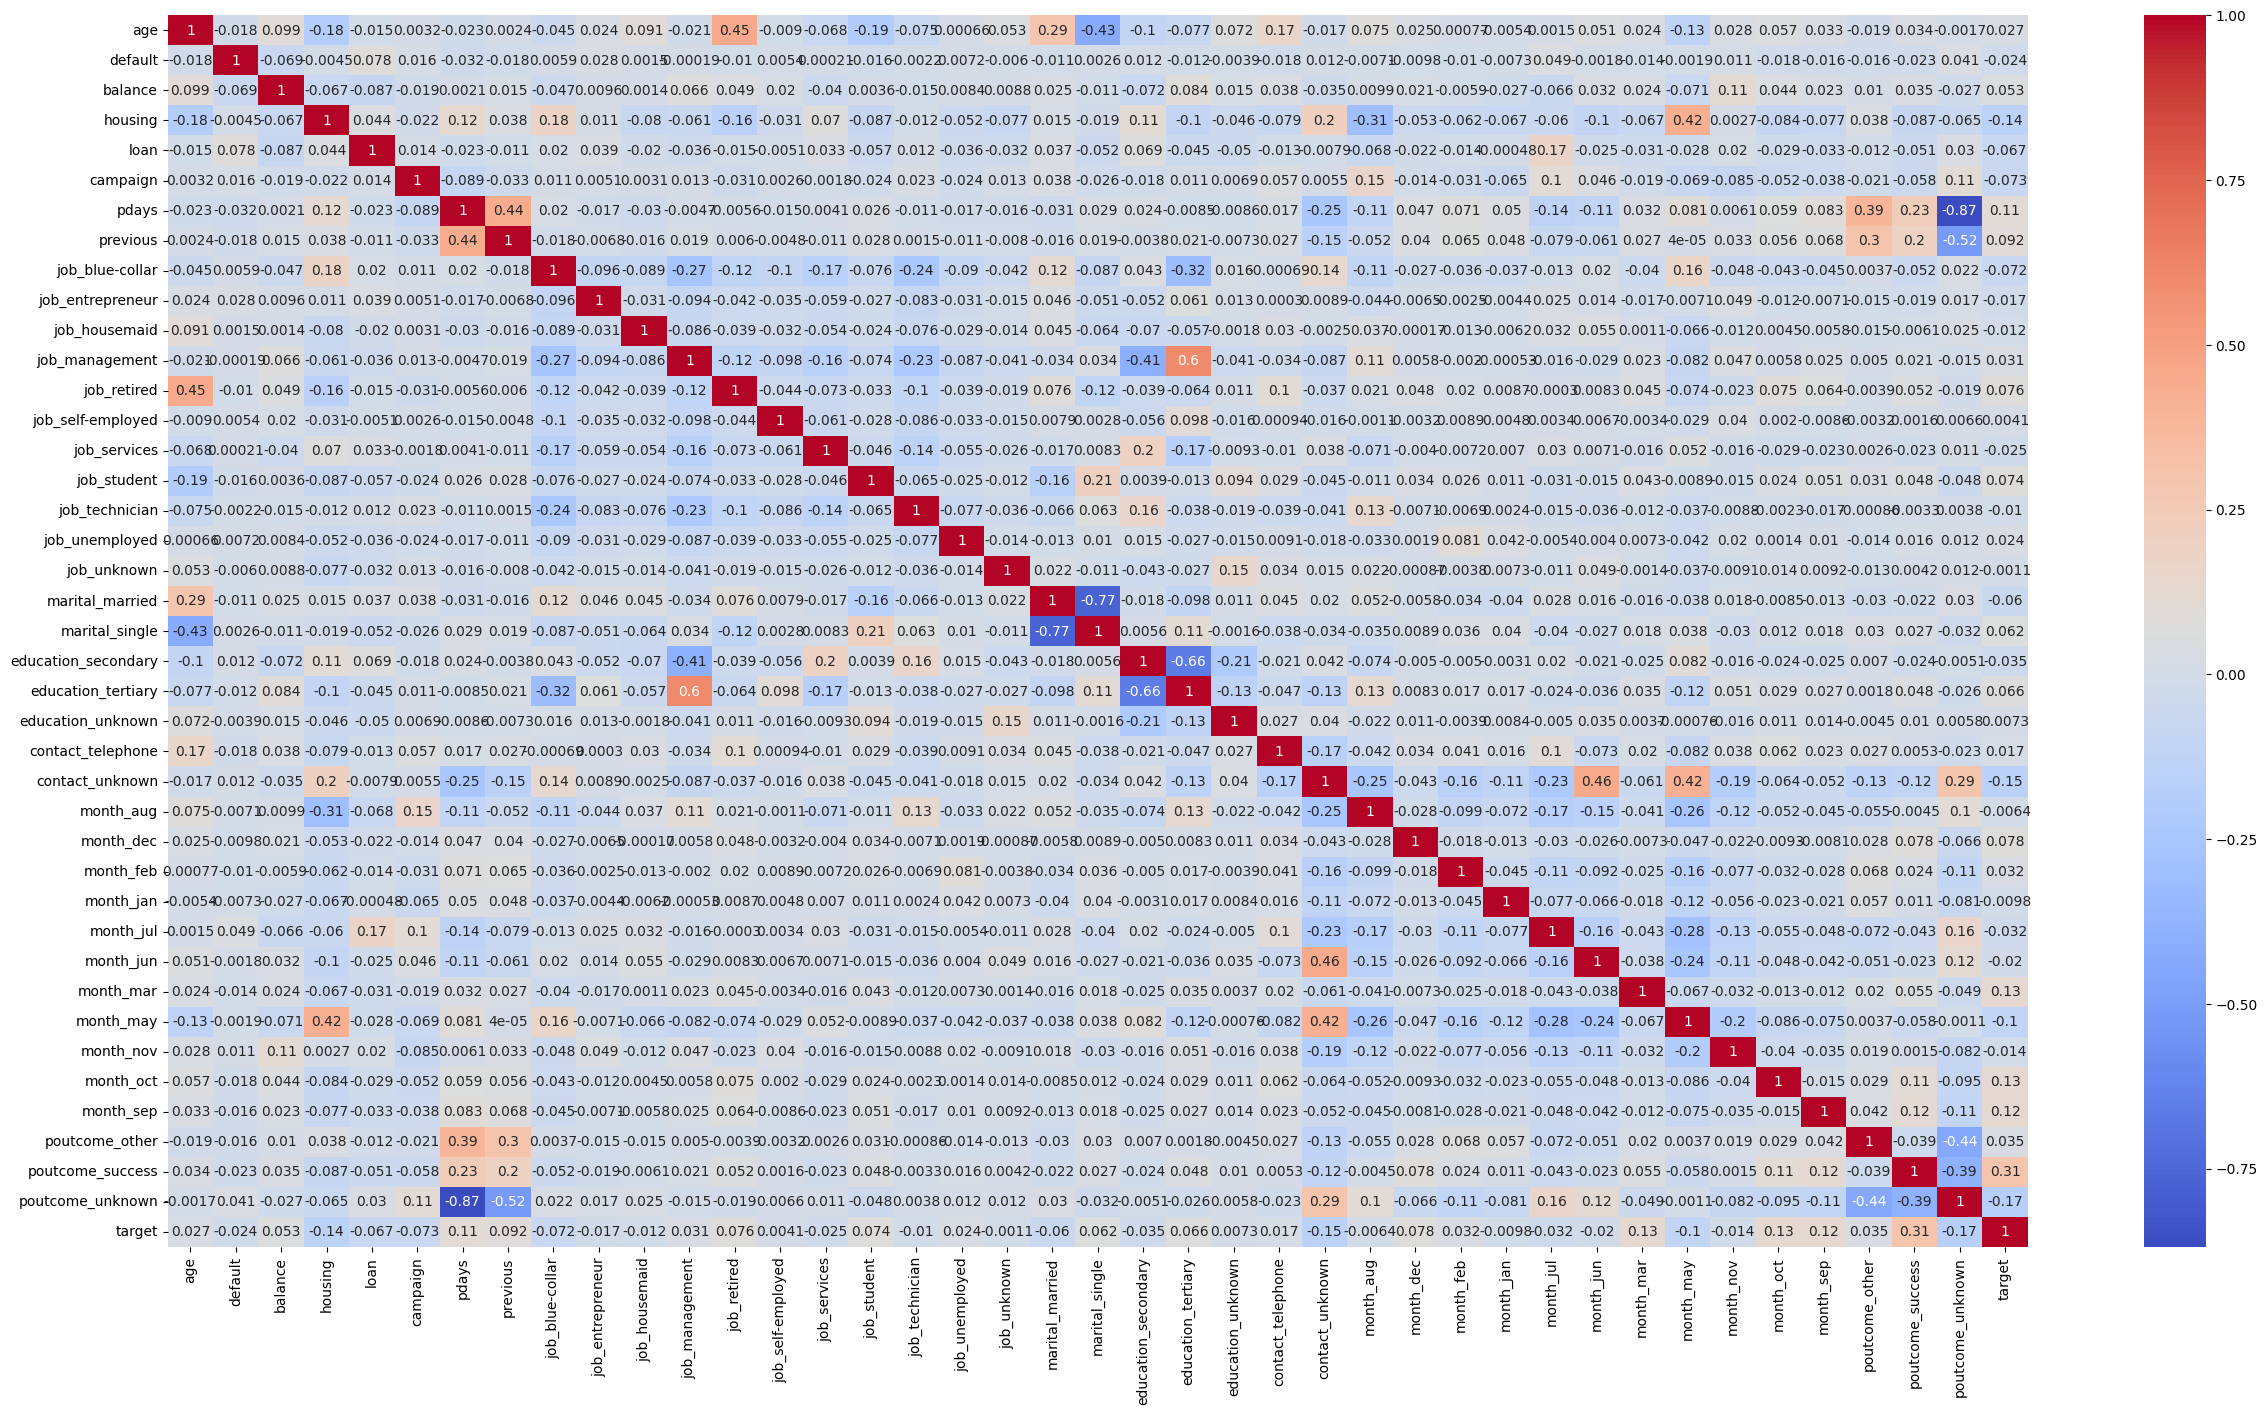

In [139]:
plt.figure(figsize=(30, 16))
sns.heatmap(train_data.corr() , annot=True , cmap='coolwarm')
plt.show()

In [140]:
features_to_drop = [
    'education_unknown',
    'job_self-employed',
    'job_unknown',
    'month_aug',
    'month_jan'
]

x_train = x_train.drop(columns=features_to_drop)
x_test = x_test.drop(columns=features_to_drop)

In [141]:
x_train.head()

,age,default,balance,housing,loan,campaign,pdays,previous,job_blue-collar,job_entrepreneur,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
3344,0.133333,0,0.295806,1,0,-0.5,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
17965,0.666667,0,0.712288,1,0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
18299,0.200000,0,2.498160,0,0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
10221,-0.133333,0,-0.416483,1,0,4.5,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
32192,1.133333,0,2.245033,0,0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [142]:
x_test.head()

,age,default,balance,housing,loan,campaign,pdays,previous,job_blue-collar,job_entrepreneur,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
3776,0.066667,0,0.097866,1,0,-0.5,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
9928,0.533333,0,2.352465,0,0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
33409,-0.933333,0,0.066961,1,0,-0.5,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
31885,0.200000,0,0.975717,0,0,-0.5,337.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
15738,1.133333,0,-0.169242,0,1,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


## SMOTE

In [143]:
y_train.value_counts() # Before SMOTE

,count
y,
0,31970
1,4198


In [144]:
from imblearn.over_sampling import SMOTE

smote = SMOTE()
x_train_smote, y_train_smote = smote.fit_resample(x_train, y_train)


In [145]:
y_train_smote.value_counts() # After SMOTE

,count
y,
0,31970
1,31970


## Machine Learning Models using SMOTE

In [146]:
models={
    'LogisticRegression':LogisticRegression( max_iter=1000),
    'DecisionTreeClassifier':DecisionTreeClassifier(),
    'RandomForestClassifier':RandomForestClassifier(),
    'SVC':SVC(),
    'KNN':KNeighborsClassifier()
}



In [147]:
result=[]
for name , model in models.items():
  model.fit(x_train_smote , y_train_smote)
  y_pred = model.predict(x_test)
  score = accuracy_score(y_pred,y_test)
  cn=confusion_matrix(y_test , y_pred)
  cr=classification_report(y_test , y_pred)
  result.append({'model': name , 'score': score , 'confusion_matrix':cn , 'classification_report':cr})



for res in result:
    print(f"Model: {res['model']}")
    print(f"Accuracy: {res['score']:.4f}")
    print("\nConfusion Matrix:")
    print(res['confusion_matrix'])
    print("\nClassification Report:")
    print(res['classification_report'])
    print("-" * 60)

Model: LogisticRegression
Accuracy: 0.7328

Confusion Matrix:
[[5954 1998]
 [ 418  673]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.75      0.83      7952
           1       0.25      0.62      0.36      1091

    accuracy                           0.73      9043
   macro avg       0.59      0.68      0.59      9043
weighted avg       0.85      0.73      0.77      9043

------------------------------------------------------------
Model: DecisionTreeClassifier
Accuracy: 0.8025

Confusion Matrix:
[[6944 1008]
 [ 778  313]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.87      0.89      7952
           1       0.24      0.29      0.26      1091

    accuracy                           0.80      9043
   macro avg       0.57      0.58      0.57      9043
weighted avg       0.82      0.80      0.81      9043

-------------------------------------------------------

# Machine Learning Models Using (class_weight)

In [148]:
models={
    'LogisticRegression':LogisticRegression( max_iter=1000 , class_weight='balanced'),
    'DecisionTreeClassifier':DecisionTreeClassifier(class_weight='balanced'),
    'RandomForestClassifier':RandomForestClassifier(class_weight='balanced'),
    'SVC':SVC(class_weight='balanced')
}

In [149]:
result=[]
for name , model in models.items():
  model.fit(x_train , y_train)
  y_pred = model.predict(x_test)
  score = accuracy_score(y_pred,y_test)
  cn=confusion_matrix(y_test , y_pred)
  cr=classification_report(y_test , y_pred)
  result.append({'model': name , 'score': score , 'confusion_matrix':cn , 'classification_report':cr})


for res in result:
    print(f"Model: {res['model']}")
    print(f"Accuracy: {res['score']:.4f}")
    print("\nConfusion Matrix:")
    print(res['confusion_matrix'])
    print("\nClassification Report:")
    print(res['classification_report'])
    print("-" * 60)


Model: LogisticRegression
Accuracy: 0.7480

Confusion Matrix:
[[6096 1856]
 [ 423  668]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.77      0.84      7952
           1       0.26      0.61      0.37      1091

    accuracy                           0.75      9043
   macro avg       0.60      0.69      0.61      9043
weighted avg       0.85      0.75      0.79      9043

------------------------------------------------------------
Model: DecisionTreeClassifier
Accuracy: 0.8319

Confusion Matrix:
[[7227  725]
 [ 795  296]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.91      0.90      7952
           1       0.29      0.27      0.28      1091

    accuracy                           0.83      9043
   macro avg       0.60      0.59      0.59      9043
weighted avg       0.83      0.83      0.83      9043

-------------------------------------------------------

# Deep Learning

In [150]:
x_train_smote.shape[0]

63940

In [151]:
Deep_model = Sequential()

Deep_model.add(Dense(64, activation='relu' , input_shape=(x_train_smote.shape[1],)))
Deep_model.add(Dense(32, activation='relu'))
Deep_model.add(Dense(16, activation='relu'))
Deep_model.add(Dense(1, activation='sigmoid'))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [152]:
Deep_model.compile(optimizer='adam',loss='binary_crossentropy', metrics=['accuracy'])

In [153]:
print("X_train shape:", x_train_smote.shape)
print("y_train shape:", y_train_smote.shape)

X_train shape: (63940, 35)
y_train shape: (63940,)


In [154]:
history=Deep_model.fit(x_train_smote , y_train_smote , epochs=10 , batch_size=32 , validation_split=0.2 )

##63940*(1-0.2)=51.152
##51.152/32=1599 in each Epoch


Epoch 1/10
1599/1599 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7291 - loss: 0.5638 - val_accuracy: 0.5768 - val_loss: 0.7089
Epoch 2/10
1599/1599 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7587 - loss: 0.5118 - val_accuracy: 0.6042 - val_loss: 0.6823
Epoch 3/10
1599/1599 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7630 - loss: 0.5005 - val_accuracy: 0.5980 - val_loss: 0.6832
Epoch 4/10
1599/1599 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7700 - loss: 0.4889 - val_accuracy: 0.6405 - val_loss: 0.6377
Epoch 5/10
1599/1599 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7747 - loss: 0.4789 - val_accuracy: 0.6715 - val_loss: 0.6259
Epoch 6/10
1599/1599 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7802 - loss: 0.4704 - val_accuracy: 0.6179 - val_loss: 0.7251
Epoch 7/10
1599/1599 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7844 - loss: 0.4612 - val_accuracy: 0.6905 - val_loss: 0.5632
Epoch 8/10
1599/1599 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7919 - loss: 0.4518 - 

In [155]:
print("Shape:", x_train_smote.shape)

Shape: (63940, 35)


In [156]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

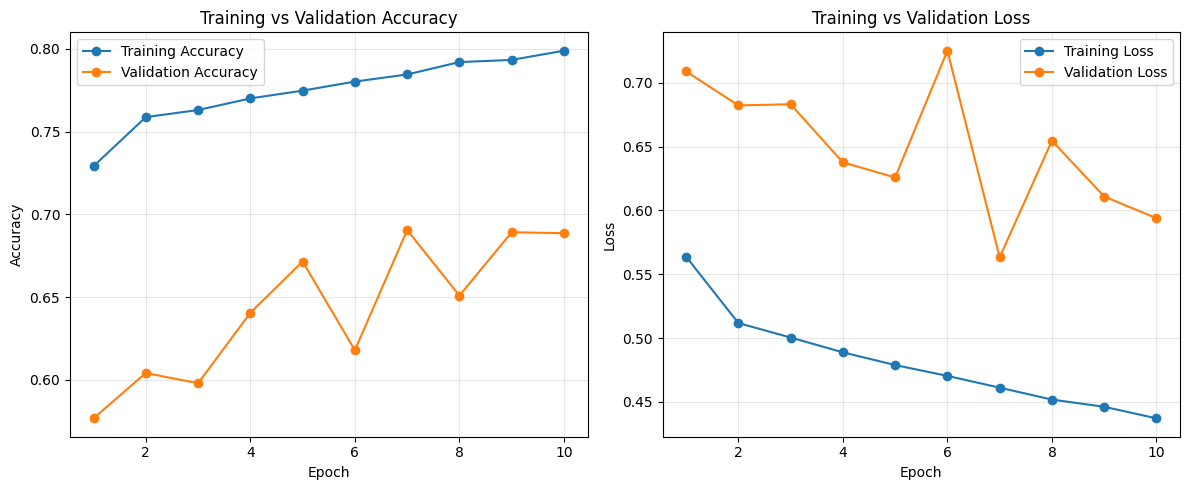

In [157]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, marker='o', label='Training Accuracy')
plt.plot(epochs_range, val_acc, marker='o', label='Validation Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, marker='o', label='Training Loss')
plt.plot(epochs_range, val_loss, marker='o', label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [158]:
Deep_model.evaluate(x_test , y_test)

283/283 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8368 - loss: 0.4097


[0.40970197319984436, 0.8367798328399658]

In [159]:
y_predection=Deep_model.predict(x_test)
pred=(y_predection>0.5).astype(int)
pred

283/283 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


array([[0],
       [0],
       [0],
       ...,
       [0],
       [0],
       [0]], shape=(9043, 1))

In [160]:
print(classification_report(y_test , pred))

              precision    recall  f1-score   support

           0       0.93      0.88      0.90      7952
           1       0.37      0.50      0.43      1091

    accuracy                           0.84      9043
   macro avg       0.65      0.69      0.67      9043
weighted avg       0.86      0.84      0.85      9043

